In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("Student Exam Performance & Success.csv")
df.head(20)

C:\Users\me\AppData\Local\Temp\ipykernel_13296\1765253602.py:1: DtypeWarning: Columns (23: sleep_hours) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Student Exam Performance & Success.csv")


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,...,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,missing,Urban,78.84,3.0,...,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,...,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,...,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,...,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low


In [5]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))
    


student_id:
student_id
STU_000655    2
STU_000855    2
STU_001187    2
STU_003773    2
STU_003961    2
STU_004180    2
STU_006090    2
STU_007091    2
STU_007705    2
STU_008904    2
STU_010883    2
STU_010944    2
STU_011053    2
STU_012314    2
STU_012765    2
Name: count, dtype: int64

age:
age
 17     14415
 18     14386
 15     14330
 20     14319
 19     14311
 14     14236
 16     14043
-5         30
 150       30
Name: count, dtype: int64

gender:
gender
Male                46554
Female              46302
Other                1944
male                  848
MALE                  843
female                838
FEMALE                810
 Female               794
 Male                 783
Unknown_Category      300
OTHER                  30
 Other                 29
other                  25
Name: count, dtype: int64

education_level:
education_level
High School      59809
Undergraduate    40291
Name: count, dtype: int64

school_type:
school_type
Public              52216
Private   

In [6]:
df["student_id"].duplicated().sum()

np.int64(100)

In [7]:
df[df["student_id"].duplicated(keep=False)].sort_values("student_id")

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
654,STU_000655,18,Female,High School,Private,Middle,Associate,Rural,60.04,2.17,...,Medium,29,96,37,94.58,9.01,36.50,F,Fail,Low
100007,STU_000655,18,Female,High School,Private,Middle,Associate,Rural,60.04,2.17,...,Medium,29,96,37,94.58,9.01,36.50,F,Fail,Low
854,STU_000855,17,Male,High School,Public,Low,Bachelor,Urban,70.49,3.09,...,Medium,14,93,65,100.0,8.59,69.18,C,Pass,Medium
100097,STU_000855,17,Male,High School,Public,Low,Bachelor,Urban,70.49,3.09,...,Medium,14,93,65,100.0,8.59,69.18,C,Pass,Medium
1186,STU_001187,16,Male,High School,Public,Low,Master,Rural,73.63,3.0,...,Medium,27,87,50,70.63,8.91,55.75,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100066,STU_095038,19,Female,High School,Private,Middle,High School,Suburban,52.76,2.18,...,Medium,19,89,49,71.32,10.00,56.83,D,Pass,Low
100053,STU_099099,18,Other,Undergraduate,Public,Middle,Master,Urban,82.01,3.5,...,Medium,3,99,48,NaN,10.00,49.69,F,Fail,Low
99098,STU_099099,18,Other,Undergraduate,Public,Middle,Master,Urban,82.01,3.5,...,Medium,3,99,48,NaN,10.00,49.69,F,Fail,Low
100045,STU_099509,15,Female,Undergraduate,Private,Lower-Middle,Associate,Urban,65.28,2.84,...,Easy,5,85,47,87.54,9.33,54.57,D,Pass,Low


In [8]:
df = df.drop_duplicates(subset=["student_id"], keep="first")

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df[~((df["age"] < 0) | (df["age"] > 100))]

In [11]:
df["age"].value_counts()


age
17    14398
18    14373
15    14319
20    14301
19    14300
14    14222
16    14027
Name: count, dtype: int64

In [12]:
text_cols = df.select_dtypes(include=["object", "string"]).columns

df[text_cols] = df[text_cols].apply(
    lambda col: col.str.strip().str.lower()
)

In [13]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))
    


student_id:
student_id
stu_000001    1
stu_000002    1
stu_000003    1
stu_000004    1
stu_000005    1
stu_000006    1
stu_000007    1
stu_000008    1
stu_000009    1
stu_000010    1
stu_000011    1
stu_000012    1
stu_000013    1
stu_000014    1
stu_000015    1
Name: count, dtype: int64

age:
age
17    14398
18    14373
15    14319
20    14301
19    14300
14    14222
16    14027
Name: count, dtype: int64

gender:
gender
male                48949
female              48666
other                2025
unknown_category      300
Name: count, dtype: int64

education_level:
education_level
high school      59714
undergraduate    40226
Name: count, dtype: int64

school_type:
school_type
public              54896
private             34791
charter              9953
unknown_category      300
Name: count, dtype: int64

family_income:
family_income
middle          30097
lower-middle    25050
low             19818
upper-middle    14891
high            10084
Name: count, dtype: int64

parent_educatio

In [14]:
df = df.replace(
    ["missing", "unknown_category"],
    np.nan
)

In [15]:
df["internet_access"].dtype


<StringDtype(storage='python', na_value=nan)>

In [16]:
df["internet_access"] = df["internet_access"].replace({
    "1": "yes",
    "y": "yes",
    "0": "no",
    "n": "no"
})

df["internet_access"].value_counts(dropna=False)

internet_access
yes    91538
no      8102
NaN      300
Name: count, dtype: int64

In [17]:
df["physical_activity_hours"].describe()

count    99940.000000
mean         2.485978
std          2.415915
min         -3.000000
25%          0.720000
50%          1.730000
75%          3.480000
max         12.000000
Name: physical_activity_hours, dtype: float64

In [18]:
df["physical_activity_hours"] = df["physical_activity_hours"].abs()
df["physical_activity_hours"].describe()

count    99940.000000
mean         2.488380
std          2.413441
min          0.000000
25%          0.720000
50%          1.730000
75%          3.480000
max         12.000000
Name: physical_activity_hours, dtype: float64

In [19]:
df.dtypes

student_id                        str
age                             int64
gender                            str
education_level                   str
school_type                       str
family_income                     str
parent_education                  str
urban_rural                       str
previous_exam_score           float64
previous_gpa                      str
attendance_percentage             str
assignment_completion_rate    float64
class_participation               str
study_hours_per_day           float64
self_study_hours              float64
private_tuition                 int64
online_learning_hours         float64
study_consistency                 str
study_environment                 str
study_method                      str
revision_frequency                str
practice_tests_completed        int64
notes_quality                     str
sleep_hours                    object
sleep_quality                     str
daily_screen_time             float64
physical_act

In [20]:
cols = [
    "previous_gpa",
    "attendance_percentage",
    "class_participation",
    "time_management_score",
    "sleep_hours"
]

for col in cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- previous_gpa ---
previous_gpa
NaN     7787
2.78     814
2.83     812
2.73     794
2.8      793
2.69     787
2.76     785
2.71     783
2.82     776
2.67     776
2.81     773
2.75     762
2.9      756
2.66     755
2.77     750
Name: count, dtype: int64

--- attendance_percentage ---
attendance_percentage
NaN      9859
100.0    2707
85.15      67
87.23      65
83.43      62
87.22      61
84.49      61
87.41      60
83.7       60
84.86      59
80.43      59
88.35      59
83.06      58
83.98      58
83.78      58
Name: count, dtype: int64

--- class_participation ---
class_participation
medium    50073
low       25139
high      24728
Name: count, dtype: int64

--- time_management_score ---
time_management_score
NaN      9607
100.0    7381
77.03      44
82.48      40
84.53      40
76.66      40
75.25      39
81.41      38
77.56      38
78.74      36
81.34      35
78.72      35
80.05      35
73.22      35
82.42      35
Name: count, dtype: int64

--- sleep_hours ---
sleep_hours
NaN     17

In [21]:
df["previous_gpa"].value_counts(dropna=False).sort_index()

previous_gpa
1.0           5
1.01          2
1.04          2
1.06          1
1.07          1
           ... 
3.99         37
4.0         454
4.0 gpa       1
unknown      40
NaN        7787
Name: count, Length: 316, dtype: int64

In [22]:
df["previous_gpa"] = (
    df["previous_gpa"]
    .astype("string")
    .str.replace(r"\s*gpa\s*", "", regex=True, case=False)
    .str.strip()
)
df["previous_gpa"].str.contains(
    
    "gpa", case=False
).sum()

np.int64(0)

In [23]:
df["previous_gpa"].value_counts(dropna=False).sort_index()

previous_gpa
1.0           5
1.01          2
1.04          2
1.06          1
1.07          1
           ... 
3.98         41
3.99         37
4.0         455
unknown      40
<NA>       7787
Name: count, Length: 298, dtype: Int64

In [24]:
df["previous_gpa"] = df["previous_gpa"].replace(
    "unknown", np.nan
)


In [25]:

numeric_cols = [
    "previous_gpa",
    "attendance_percentage",
    "time_management_score",
    "sleep_hours"
]

for col in numeric_cols:
    values = pd.to_numeric(df[col], errors="coerce")

    invalid = df.loc[
        df[col].notna() & values.isna(),
        col
    ]

    print(f"\n--- {col} ---")
    print(invalid.value_counts())


--- previous_gpa ---
Series([], Name: count, dtype: Int64)

--- attendance_percentage ---
attendance_percentage
ninety    30
80%        4
79%        4
92%        3
85%        3
90%        3
88%        3
87%        2
100%       2
82%        2
63%        1
81%        1
94%        1
93%        1
84%        1
98%        1
68%        1
86%        1
97%        1
89%        1
73%        1
70%        1
76%        1
78%        1
Name: count, dtype: int64

--- time_management_score ---
Series([], Name: count, dtype: int64)

--- sleep_hours ---
sleep_hours
8 hours     14
7 hours     10
6 hours      7
5 hours      6
9 hours      2
10 hours     1
Name: count, dtype: int64


In [26]:
# حذفت ال ninety
df["attendance_percentage"] = df["attendance_percentage"].replace(
    "ninety", "90"
)
# حذفت ال %
df["attendance_percentage"] = (
    df["attendance_percentage"]
    .astype("string")
    .str.replace("%", "")
    .str.strip()
)

In [27]:
df["sleep_hours"] = (
    df["sleep_hours"]
    .astype("string")
    .str.replace("hours", "")
    .str.strip()
)

In [28]:
#هحولهم لارقام 
numeric_cols = [
    "previous_gpa",
    "attendance_percentage",
    "time_management_score",
    "sleep_hours"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="raise")

#########################################################
df[numeric_cols].dtypes

previous_gpa             Float64
attendance_percentage    Float64
time_management_score    float64
sleep_hours              Float64
dtype: object

In [29]:
median_gpa=df["previous_gpa"].median()
df["previous_gpa"] = df["previous_gpa"].fillna(median_gpa)


In [30]:
df["previous_gpa"].value_counts().head(20)

previous_gpa
2.78    8641
2.83     812
2.8      795
2.73     794
2.69     787
2.76     785
2.71     783
2.82     776
2.67     776
2.81     773
2.9      762
2.75     762
2.66     755
2.77     750
2.65     748
2.89     746
2.68     746
2.97     744
2.84     741
2.86     740
Name: count, dtype: Int64

In [31]:
# ايه الاعمده اللي فيها missing data 
missing_data = df.isnull().sum()

missing_data = missing_data[missing_data > 0]

missing_data

gender                    300
school_type               300
parent_education         6522
urban_rural               300
attendance_percentage    9859
notes_quality            8402
sleep_hours              1733
sleep_quality            6989
internet_access           300
device_availability      2962
time_management_score    9607
dtype: int64

In [32]:
# handle missing value ==>gender
# missing value ==>0.3% ==> بس هياثر
df["gender"] = df["gender"].fillna("unknown")
df["gender"].value_counts(dropna=False)


gender
male       48949
female     48666
other       2025
unknown      300
Name: count, dtype: int64

In [33]:
df["attendance_percentage"].describe()

count     90081.0
mean     84.64625
std      8.038438
min         46.34
25%         79.22
50%         84.76
75%         90.17
max         150.0
Name: attendance_percentage, dtype: Float64

In [34]:
((df["attendance_percentage"] > 100) ).sum()

np.int64(40)

In [35]:
df.loc[df["attendance_percentage"] > 100, "attendance_percentage"] = np.nan
df["attendance_percentage"].isna().sum()

np.int64(9899)

In [36]:
# handle missing value ==> attendance_percentage
df["attendance_percentage"] = df["attendance_percentage"].fillna(
    df["attendance_percentage"].median()
)

In [37]:
df["time_management_score"].describe()

count    90333.000000
mean        78.396359
std         14.105745
min         17.030000
25%         68.790000
50%         78.990000
75%         89.210000
max        100.000000
Name: time_management_score, dtype: float64

In [38]:
df["time_management_score"] = df["time_management_score"].fillna(
    df["time_management_score"].median()
)

In [39]:
df["school_type"].value_counts(dropna=False)

school_type
public     54896
private    34791
charter     9953
NaN          300
Name: count, dtype: int64

In [40]:
df["school_type"] = df["school_type"].fillna("unknown")

In [41]:
df["urban_rural"] = df["urban_rural"].fillna("unknown")

In [42]:
df["sleep_hours"].describe()

count     98207.0
mean     7.003579
std      1.264839
min           3.0
25%          6.18
50%           7.0
75%          7.81
max          27.0
Name: sleep_hours, dtype: Float64

In [43]:
df.loc[
    (df["sleep_hours"] < 0) | (df["sleep_hours"] > 24),
    "sleep_hours"
].value_counts()

sleep_hours
27.0    39
Name: count, dtype: Int64

In [44]:
df = df[~(df["sleep_hours"] > 24)]

In [45]:
df["sleep_quality"] = df["sleep_quality"].fillna(df["sleep_quality"].mode()[0])
df["sleep_quality"].isna().sum()

np.int64(0)

In [46]:
df["sleep_hours"] = df["sleep_hours"].fillna(df["sleep_hours"].median())

In [47]:
df["parent_education"] = df["parent_education"].fillna("unknown")

In [48]:
df["notes_quality"] = df["notes_quality"].fillna("unknown")

In [49]:
df["device_availability"] = df["device_availability"].fillna("unknown")

In [50]:
df["internet_access"] = df["internet_access"].fillna(df["internet_access"].mode()[0])

In [51]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,daily_screen_time,physical_activity_hours,stress_level,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,98168.000000,98168.000000,98168.0,98168.0,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,...,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000,98168.000000
mean,17.007008,69.527875,2.780754,84.635122,69.724561,2.995867,2.094960,0.299609,2.005020,5.507416,...,5.000022,2.487926,9.376080,2.997815,15.499093,92.493256,57.321103,78.444427,8.927389,61.942712
std,1.999504,11.375564,0.459066,7.518774,12.125635,1.719773,1.265982,0.458089,2.006414,2.501753,...,1.775930,2.413818,1.081416,2.980534,8.644892,4.611273,15.058286,13.414389,1.355379,15.938889
min,14.000000,30.000000,1.0,46.34,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,1.000000,0.000000,5.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,-10.000000
25%,15.000000,61.820000,2.49,79.91,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,3.770000,0.720000,9.000000,0.860000,8.000000,88.000000,47.000000,69.970000,8.220000,51.237500
50%,17.000000,69.520000,2.78,84.75,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,4.990000,1.730000,10.000000,2.080000,16.000000,92.000000,57.000000,78.990000,9.490000,61.965000
75%,19.000000,77.230000,3.07,89.5,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,6.210000,3.470000,10.000000,4.150000,23.000000,97.000000,67.000000,87.970000,10.000000,72.720000
max,20.000000,100.000000,4.0,100.0,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.080000,12.000000,10.000000,20.000000,30.000000,100.000000,109.000000,100.000000,10.000000,120.000000


In [52]:
(df["exam_score"] < 0).sum()

np.int64(30)

In [53]:
df = df[df["exam_score"] >= 0]

In [54]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,daily_screen_time,physical_activity_hours,stress_level,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,98138.000000,98138.000000,98138.0,98138.0,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,...,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000,98138.000000
mean,17.006970,69.528258,2.780764,84.635123,69.725444,2.996007,2.095058,0.299619,2.005014,5.507377,...,4.999952,2.487932,9.376052,2.997982,15.498522,92.493071,57.321028,78.443523,8.927435,61.964704
std,1.999458,11.375970,0.459098,7.518766,12.125378,1.719839,1.266038,0.458093,2.006454,2.501913,...,1.776028,2.413939,1.081432,2.980813,8.644647,4.611413,15.059509,13.414422,1.355440,15.891607
min,14.000000,30.000000,1.0,46.34,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,1.000000,0.000000,5.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.49,79.91,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,3.770000,0.720000,9.000000,0.860000,8.000000,88.000000,47.000000,69.970000,8.220000,51.250000
50%,17.000000,69.520000,2.78,84.75,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,4.990000,1.730000,10.000000,2.080000,16.000000,92.000000,57.000000,78.990000,9.490000,61.970000
75%,19.000000,77.230000,3.07,89.5,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,6.210000,3.470000,10.000000,4.150000,23.000000,97.000000,67.000000,87.970000,10.000000,72.720000
max,20.000000,100.000000,4.0,100.0,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.080000,12.000000,10.000000,20.000000,30.000000,100.000000,109.000000,100.000000,10.000000,120.000000


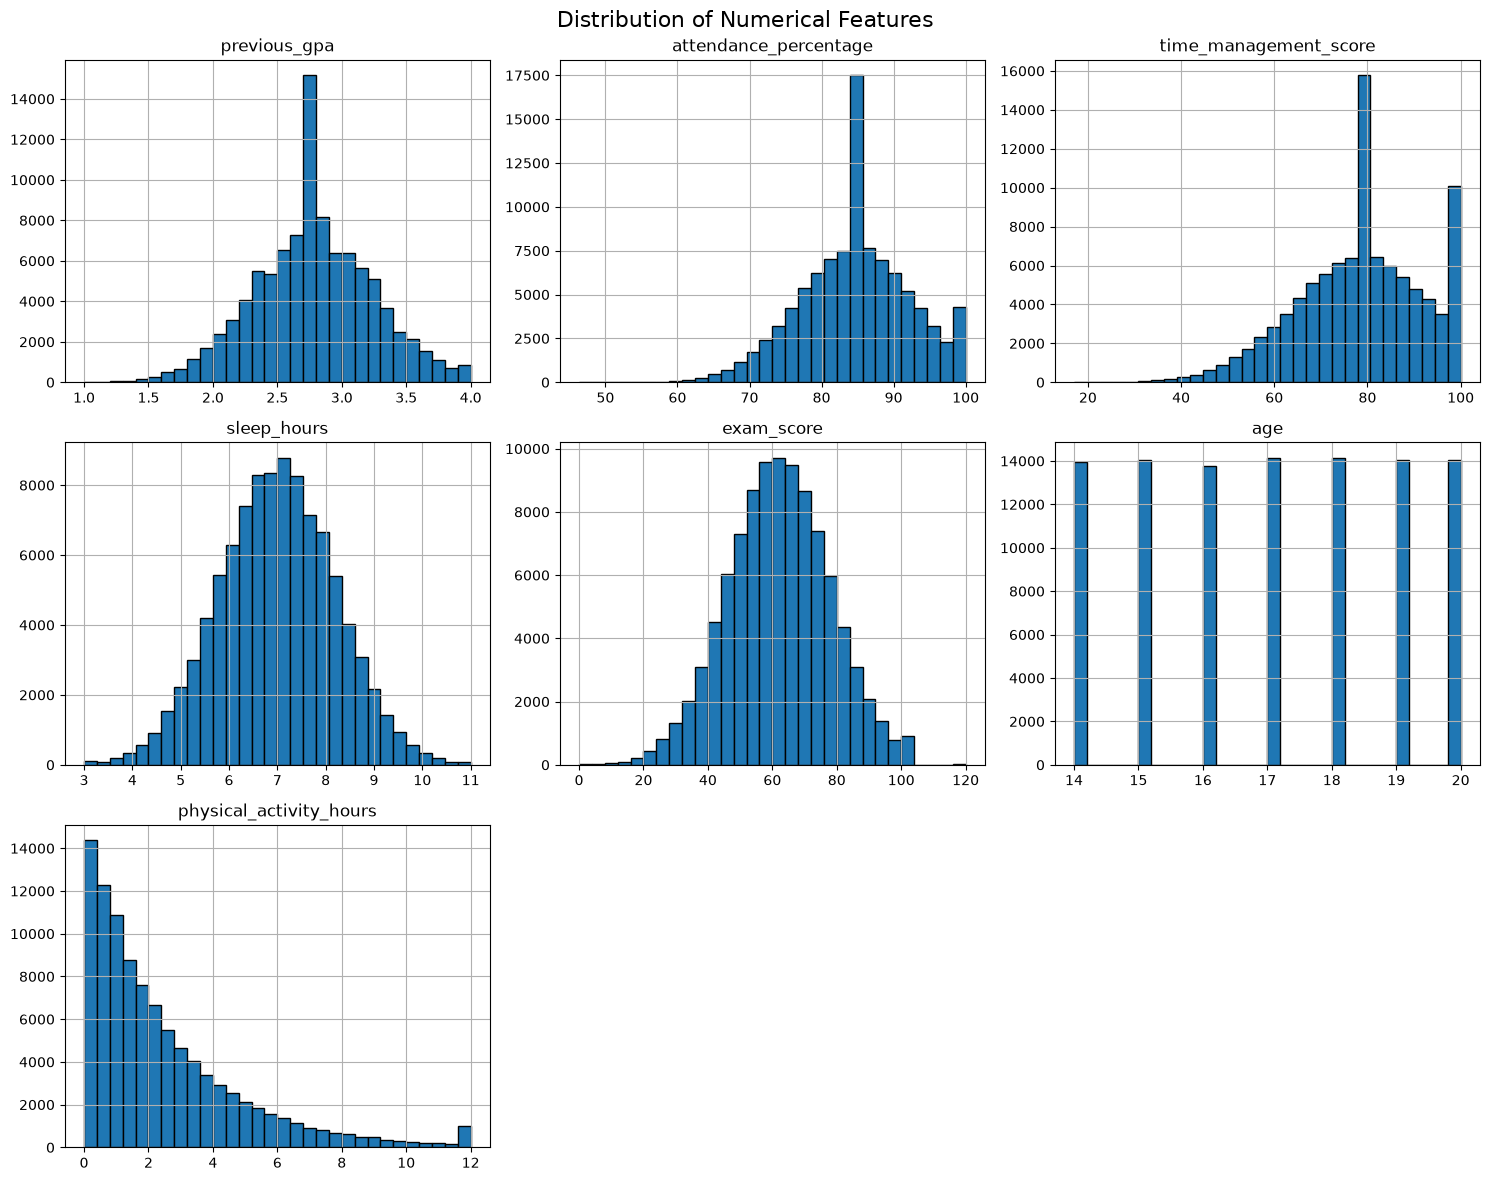

In [55]:
numeric_cols = [
    "previous_gpa",
    "attendance_percentage",
    "time_management_score",
    "sleep_hours",
    "exam_score",
    "age",
    "physical_activity_hours"
]
df[numeric_cols].describe()
df[numeric_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()